# Summary

This notebook contains the steps to fine tune a vision model from fastai to be able to classify cats and dogs breeds. It can be considered an extension of [fine tunning the model to classify cats vs dogs](https://github.com/mquirosdev/deep-learning-for-coders/blob/main/01_intro/fastai-cat-vs-dogs.ipynb)

We will start by installing the dependencies:

In [1]:
!pip install -Uqq fastai

Now we can proceed to create the `Dataloaders` by using `ImageDataLoaders.from_name_func`. By displaying a batch of our data we can check that every image is being labeled with the breed of the animal (ex: file name "shiba_inu_123" is labeled as "shiba_inu"). 

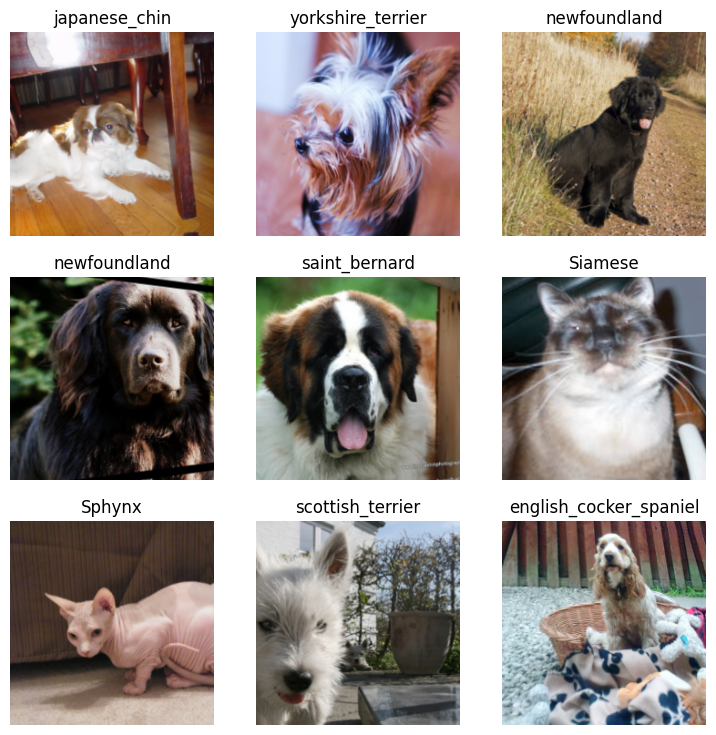

In [13]:
# import all the classes and variables in fastai.vision.all
from fastai.vision.all import *

path = untar_data(URLs.PETS)

def exact_breed_from_file_name(file_name):
    components = file_name.split("_")
    components.pop();
    return "_".join(components)
    
file_paths = get_image_files(path/"images")

dls = ImageDataLoaders.from_name_func(
    path,
    file_paths,
    exact_breed_from_file_name,
    item_tfms=Resize(224),
    batch_tfms=aug_transforms(size=224)
)

dls.show_batch()

Now that we have defined how our model will going to consume the data using a learner so we can use fine tune on a pretrained model (resnet). In this case we will train for just one epoch

In [14]:
learner = vision_learner(dls, resnet34, metrics=error_rate)
learner.fine_tune(1)

epoch,train_loss,valid_loss,error_rate,time
0,1.509179,0.323662,0.101489,00:29


epoch,train_loss,valid_loss,error_rate,time
0,0.491016,0.291612,0.090663,00:38


Now that the model is fined tuned we can make predictions

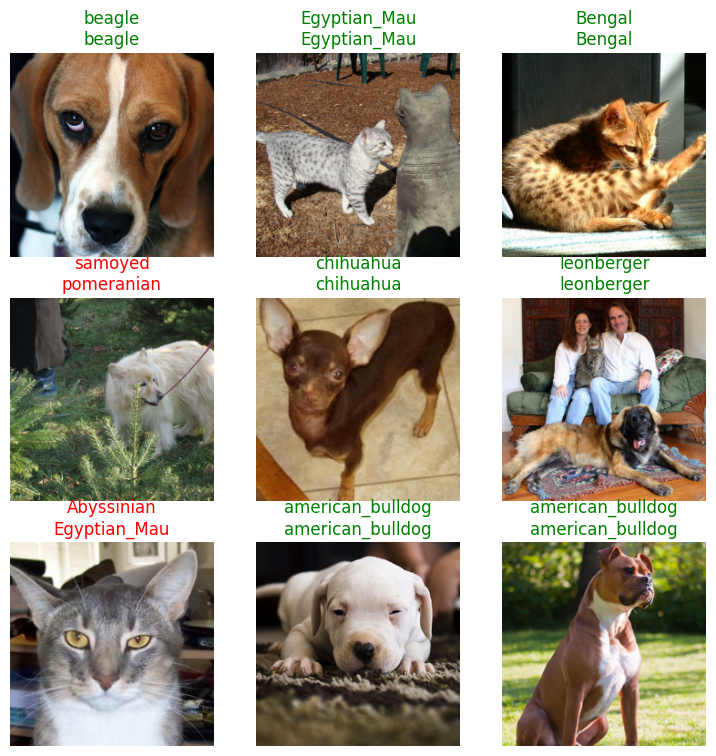

In [22]:
learner.show_results()